# AdaSym: diagnóstico do boost direcional

**Pesquisa experimental de Ítalo Capuzzo — LeNet/Fashion-MNIST, 150 épocas, piso v/4.**

A análise dos dados participa da investigação da regra de atualização: identificação de padrões, comparação de variantes e revisão das hipóteses. O diagnóstico dos contadores examina o boost element-wise produzido pela janela de consistência dos gradientes.

Requer o pacote instalado com `.[plots]` e um ambiente Jupyter.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/original/AdaSym_fminist_full.npy').exists())
sys.path.insert(0,str(ROOT/'src'))
from optimizer_research.diagnostics import boost_diagnostics
c4,c2,full=[np.load(ROOT/'data/original'/f'AdaSym_fminist_{s}.npy',allow_pickle=False) for s in ('c4','c2','full')]
d=boost_diagnostics(c4,c2,full)
d4,d2,df=d['increments']
epochs=np.arange(1,len(full)+1)
print('Intervalos registrados:',len(full))
for name,a in zip(('c4','c2','full'),(c4,c2,full)):
    print(f'{name}: {int(a[-1]):,}')

Intervalos registrados: 150
c4: 145,766,992,885
c2: 205,636,961,999
full: 1,460,922,532,104


## 1. Registros do mecanismo de boost

`full` está associado ao boost integral limitado pelo threshold. `c4` e `c2` acompanham faixas de boost parcial relacionadas a v/4 e v/2, com **c4 incluído em c2**. As séries acumuladas são convertidas em incrementos para a análise por intervalo.

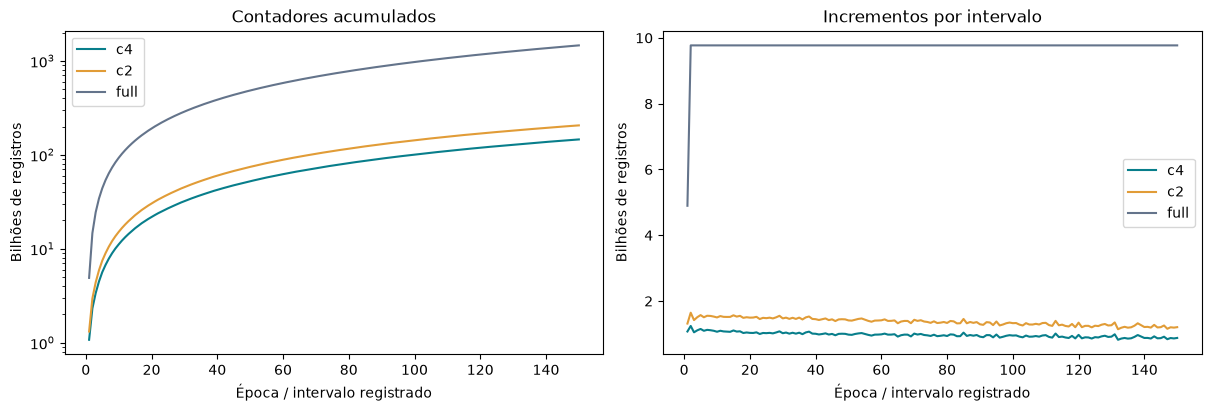

In [2]:
assert all(a<=b for a,b in zip(d4,d2))
for delta,a in zip((d4,d2,df),(c4,c2,full)):
    assert sum(delta)==int(a[-1])
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for name,a,delta,color in zip(('c4','c2','full'),(c4,c2,full),(d4,d2,df),['#087e8b','#e19c37','#64748b']):
    ax[0].plot(epochs,a/1e9,label=name,color=color)
    ax[1].plot(epochs,np.asarray(delta,dtype=float)/1e9,label=name,color=color)
ax[0].set(title='Contadores acumulados',yscale='log',ylabel='Bilhões de registros')
ax[1].set(title='Incrementos por intervalo',ylabel='Bilhões de registros')
for a in ax:
    a.set_xlabel('Época / intervalo registrado')
    a.legend()
plt.show()

## 2. Composição interna de c2

A partição de c2 em c4 e c2 fora de c4 permite examinar a composição sem dupla contagem. A normalização é feita dentro de c2.

c4 dentro de c2: 70.886%
c2 fora de c4: 29.114%


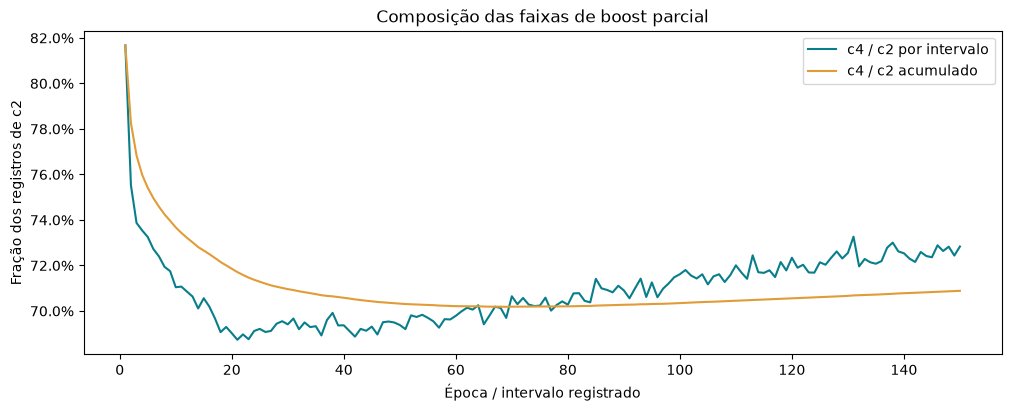

In [3]:
share=float(c4[-1]/c2[-1])
print(f'c4 dentro de c2: {share:.3%}')
print(f'c2 fora de c4: {1-share:.3%}')
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
ax.plot(epochs,d['within_c2'][0],label='c4 / c2 por intervalo',color='#087e8b')
ax.plot(epochs,c4/c2,label='c4 / c2 acumulado',color='#e19c37')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Época / intervalo registrado',ylabel='Fração dos registros de c2',title='Composição das faixas de boost parcial')
ax.legend()
plt.show()

## 3. Evolução por fase

As janelas agregam as contagens antes de calcular a composição. A largura da janela pode ser alterada para examinar diferentes escalas temporais.

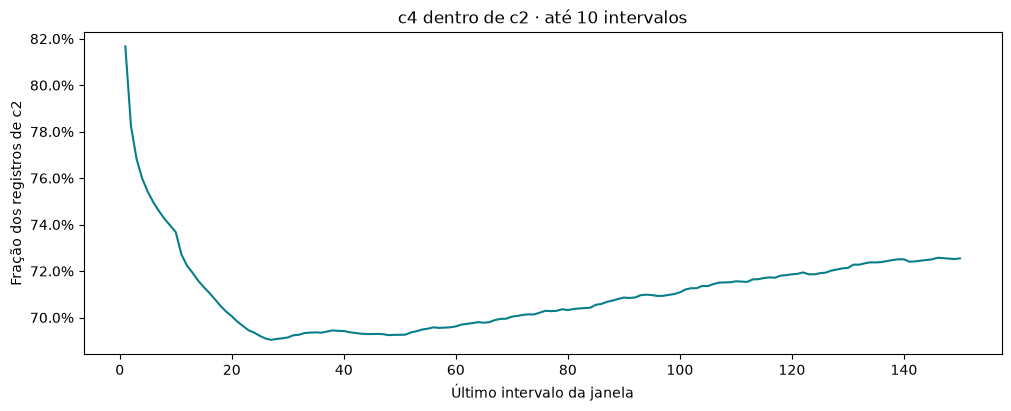

  1– 10: c4 dentro de c2 = 73.673%
 11– 40: c4 dentro de c2 = 69.543%
 41– 70: c4 dentro de c2 = 69.632%
 71–100: c4 dentro de c2 = 70.750%
101–130: c4 dentro de c2 = 71.847%
131–150: c4 dentro de c2 = 72.525%


In [4]:
window=10
rolling=np.array([float(sum(d4[max(0,i-window+1):i+1])/sum(d2[max(0,i-window+1):i+1])) for i in range(len(full))])
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
ax.plot(epochs,rolling,color='#087e8b')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel='Último intervalo da janela',ylabel='Fração dos registros de c2',title=f'c4 dentro de c2 · até {window} intervalos')
plt.show()
for start,stop in [(0,10),(10,40),(40,70),(70,100),(100,130),(130,150)]:
    a,b=int(sum(d4[start:stop])),int(sum(d2[start:stop]))
    print(f'{start+1:3d}–{stop:3d}: c4 dentro de c2 = {a/b:.3%}')

## 4. Relação com a evolução da fórmula

A pesquisa combina análise dos experimentos e diagnóstico interno do otimizador. A sequência da formulação reúne expressão descoberta, memória ao quadrado, piso relativo, memória separada e sigmoide. Os contadores examinam o mecanismo de boost; as curvas de loss e as varreduras complementam a investigação do comportamento experimental.

O [relatório](../results/research/report.md) reúne figuras, métricas por trajetória e tabelas. A metodologia está em [investigacao_dados.md](../docs/investigacao_dados.md).